In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import plotly.graph_objs as go
from plotly.subplots import make_subplots
from IPython.display import display, clear_output

In [2]:
# Create data
np.random.seed(42)
x = np.linspace(0, 2*np.pi, 104)  

# Combine multiple sine and cosine functions
y = np.sin(x) + 0.5*np.sin(2*x) + 0.3*np.cos(3*x) + 0.6*np.sin(4*x) + 0.1*np.random.randn(104)

# Convert data to PyTorch tensors
x_tensor = torch.tensor(x, dtype=torch.float32).view(-1, 1)
y_tensor = torch.tensor(y, dtype=torch.float32).view(-1, 1)

# Normalize the x data for better training performance
x_min, x_max = x_tensor.min(), x_tensor.max()
x_normalized = (x_tensor - x_min) / (x_max - x_min)

In [3]:
def visualize_nn(layer_sizes, title="Neural Network Architecture", max_neurons_display=12):
    """
    Visualize a neural network architecture using matplotlib.
    
    Args:
        layer_sizes: List of integers representing neurons in each layer, e.g., [1, 12, 1]
        title: Title for the plot
        max_neurons_display: Maximum neurons to display for the LARGEST layer (others scaled proportionally)
    """
    fig, ax = plt.subplots(figsize=(14, 8))
    
    n_layers = len(layer_sizes)
    max_neurons = max(layer_sizes)
    layer_positions = np.linspace(0.1, 0.9, n_layers)
    
    # Colors for different layer types
    colors = {
        'input': '#3498db',    # Blue
        'hidden': '#2ecc71',   # Green
        'output': '#e74c3c'    # Red
    }
    
    neuron_positions = {}  # Store positions for drawing connections
    
    for layer_idx, (x_pos, n_neurons) in enumerate(zip(layer_positions, layer_sizes)):
        # Determine layer type
        if layer_idx == 0:
            layer_type = 'input'
            layer_name = f'Input\n({n_neurons})'
        elif layer_idx == n_layers - 1:
            layer_type = 'output'
            layer_name = f'Output\n({n_neurons})'
        else:
            layer_type = 'hidden'
            layer_name = f'Hidden {layer_idx}\n({n_neurons})'
        
        color = colors[layer_type]
        
        # Scale displayed neurons PROPORTIONALLY to preserve shape
        # Largest layer gets max_neurons_display, others get proportionally fewer
        if max_neurons <= max_neurons_display:
            display_neurons = n_neurons
            show_ellipsis = False
        else:
            # Proportional scaling - maintain the ratio
            display_neurons = max(1, int(round(n_neurons / max_neurons * max_neurons_display)))
            show_ellipsis = n_neurons > display_neurons
        
        # Calculate y positions for neurons - centered vertically
        if display_neurons == 1:
            y_positions = [0.5]
        else:
            # Scale the spread based on number of neurons to show relative sizes
            spread = 0.8 * (display_neurons / max_neurons_display)
            spread = max(0.1, spread)  # Minimum spread
            y_positions = np.linspace(0.5 - spread/2, 0.5 + spread/2, display_neurons)
        
        neuron_positions[layer_idx] = []
        
        # Adjust circle size based on how many neurons to display
        circle_radius = 0.02 if max_neurons_display <= 12 else 0.015
        
        for i, y_pos in enumerate(y_positions):
            # Draw neuron
            circle = plt.Circle((x_pos, y_pos), circle_radius, color=color, ec='black', linewidth=1.5, zorder=3)
            ax.add_patch(circle)
            neuron_positions[layer_idx].append((x_pos, y_pos))
        
        # Add ellipsis if neurons were truncated
        if show_ellipsis:
            ax.text(x_pos, 0.5, '...', fontsize=10, ha='center', va='center', 
                   fontweight='bold', color='gray', zorder=4)
        
        # Layer label
        ax.text(x_pos, 0.02, layer_name, fontsize=10, ha='center', va='top', fontweight='bold')
    
    # Draw connections between layers
    for layer_idx in range(n_layers - 1):
        for (x1, y1) in neuron_positions[layer_idx]:
            for (x2, y2) in neuron_positions[layer_idx + 1]:
                ax.plot([x1, x2], [y1, y2], 'gray', alpha=0.2, linewidth=0.5, zorder=1)
    
    # Styling
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.05, 1.05)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(title, fontsize=14, fontweight='bold', pad=10)
    
    # Add legend
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor=colors['input'], edgecolor='black', label='Input Layer'),
        Patch(facecolor=colors['hidden'], edgecolor='black', label='Hidden Layer'),
        Patch(facecolor=colors['output'], edgecolor='black', label='Output Layer')
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=9)
    
    plt.tight_layout()
    plt.show()
    
    # Print parameter count
    total_params = 0
    print("Layer connections:")
    for i in range(len(layer_sizes) - 1):
        weights = layer_sizes[i] * layer_sizes[i+1]
        biases = layer_sizes[i+1]
        layer_params = weights + biases
        total_params += layer_params
        print(f"  Layer {i} -> {i+1}: {layer_sizes[i]} x {layer_sizes[i+1]} = {weights} weights + {biases} biases = {layer_params} params")
    print(f"  Total parameters: {total_params:,}")


def get_layer_sizes(model):
    """Extract layer sizes from a PyTorch model with Linear layers."""
    sizes = []
    for name, layer in model.named_modules():
        if isinstance(layer, nn.Linear):
            if not sizes:  # First layer - add input size
                sizes.append(layer.in_features)
            sizes.append(layer.out_features)
    return sizes


# Example usage:
# visualize_nn([1, 12, 1], "SimpleNet Architecture")
# visualize_nn([1, 64, 128, 128, 64, 1], "OverfitNet Architecture")

In [4]:
def flatten_tensors(tensor_list):
    """
    Takes a list of n Tensors of any dimension and returns a single linear list of all the values in the Tensors.

    Args:
    tensor_list (list of torch.Tensor): List of tensors to be flattened.

    Returns:
    list: A single list containing all the values from the tensors.
    """
    # Initialize an empty list to store the flattened values
    flattened_values = []

    # Iterate through each tensor in the list
    for tensor in tensor_list:
        # Flatten the tensor and extend the flattened values to the list
        flattened_values.extend(tensor.flatten().tolist())

    return flattened_values

# Example usage:
# tensor_list = list(model.parameters())
# flattened_result = flatten_tensors(tensor_list)
# type(flattened_result[0])



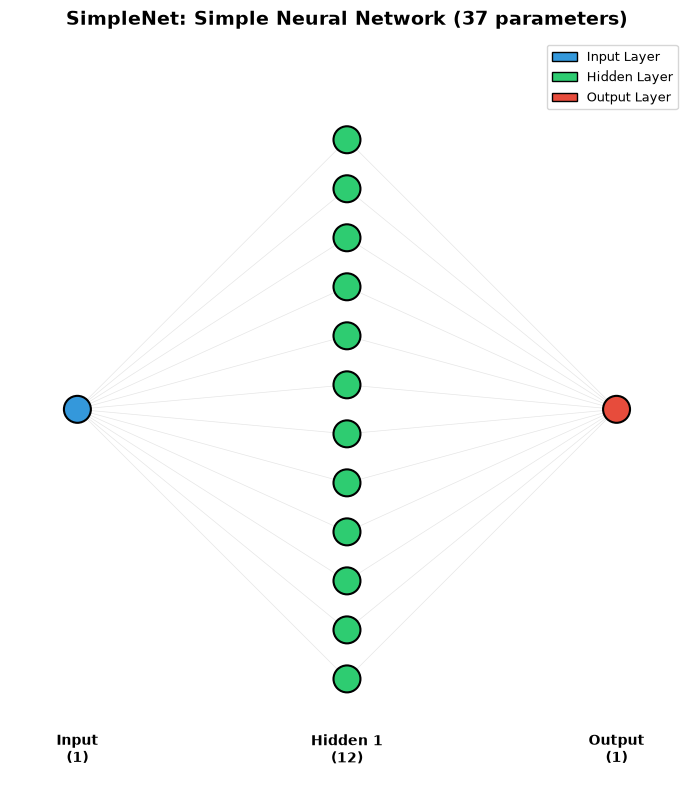

Layer connections:
  Layer 0 -> 1: 1 x 12 = 12 weights + 12 biases = 24 params
  Layer 1 -> 2: 12 x 1 = 12 weights + 1 biases = 13 params
  Total parameters: 37


In [5]:
# Visualize SimpleNet architecture (used in next cell)
visualize_nn([1, 12, 1], "SimpleNet: Simple Neural Network (37 parameters)")

In [6]:
# Define a simple neural network 

import os

# Toggle state using an environment variable
state_file = '/tmp/nn0_toggle_state.txt'
if os.path.exists(state_file):
    with open(state_file, 'r') as f:
        current_state = int(f.read().strip())
else:
    current_state = 0

# Toggle to next state
next_state = 1 - current_state
with open(state_file, 'w') as f:
    f.write(str(next_state))

class SimpleNet(nn.Module):
    def __init__(self):
        super(SimpleNet, self).__init__()
        self.fc1 = nn.Linear(1, 12)  # 12 neurons in the hidden layer
        self.fc2 = nn.Linear(12, 1)

    def forward(self, x):
        x = torch.sigmoid(self.fc1(x))
        return self.fc2(x)


if current_state == 0:
    model = SimpleNet()  # a fresh, untrained network
    # STATE 0: Show all parameters as zero
    with torch.no_grad():
        for param in model.parameters():
            param.zero_()
    
    # Create visualization with zero parameters
    trace_data = go.Scatter(x=x, y=y, mode='markers', name='Data')
    trace_fit = go.Scatter(
        x=x,
        y=model(x_normalized).detach().numpy().flatten(),
        mode='lines',
        name='Predicted'
    )
    
    parameter_values = flatten_tensors(list(model.parameters()))
    colors = ['red' if val < 0 else 'green' for val in parameter_values]
    trace_parameters = go.Bar(
        x=list(range(len(parameter_values))), 
        y=parameter_values,
        name='Parameters',
        marker_color=colors
    )
    
    trace_loss = go.Scatter(
        x=[0],
        y=[0],
        mode='lines',
        name='Loss',
        line=dict(color='blue')
    )
    
    fig = make_subplots(
        rows=2, cols=2, 
        column_widths=[0.7, 0.3],
        row_heights=[0.6, 0.4],
        subplot_titles=('Data Fit', 'Parameters', 'Training Loss'),
        specs=[[{"rowspan": 2}, {}],
               [None, {}]]
    )
    
    fig.add_trace(trace_data, row=1, col=1)
    fig.add_trace(trace_fit, row=1, col=1)
    fig.add_trace(trace_parameters, row=1, col=2)
    fig.add_trace(trace_loss, row=2, col=2)
    
    fig.update_yaxes(range=[-40, 40], row=1, col=2)
    fig.update_xaxes(row=1, col=1)
    fig.update_xaxes(row=1, col=2)
    fig.update_xaxes(row=2, col=2)
    fig.update_yaxes(row=1, col=1)
    fig.update_yaxes(row=1, col=2)
    fig.update_yaxes(range=[0, None], row=2, col=2)
    
    fig.update_layout(
        title='Parameters Initialized to Zero - Run again to train', 
        width=1400, 
        height=800,
        showlegend=True
    )
    
    fig.show()

else:
    # STATE 1: Perform gradient descent
    # Create a fresh model for training

    # Create the model, loss function, and an optimizer with learning rate
    model = SimpleNet()
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.003)

    # Creating a scatter plot of the data and a line plot for the model's predictions
    trace_data = go.Scatter(x=x, y=y, mode='markers', name='Data')
    trace_fit = go.Scatter(x=x, y=model(x_normalized).detach().numpy().flatten(), mode='lines', name='Fit')

    num_epochs = 20000
    losses = []
    for epoch in range(num_epochs):
        optimizer.zero_grad()  # Reset gradients
        outputs = model(x_normalized)
        loss = criterion(outputs, y_tensor)
        loss.backward()  # Compute gradients
        optimizer.step()  # Update weights
        
        losses.append(loss.item())

        if epoch == 0 or (epoch+1) % 50 == 0:  # Updating 
            # Clear the previous figure
            clear_output(wait=True)
            
            # Update trace with the current model prediction
            trace_fit_updated = go.Scatter(
                x=x,
                y=model(x_normalized).detach().numpy().flatten(),
                mode='lines',
                name='Predicted'
            )
            
            # Create a bar trace for the parameter values (now vertical orientation)
            parameter_values = flatten_tensors(list(model.parameters()))
            colors = ['red' if val < 0 else 'green' for val in parameter_values]
            trace_parameters = go.Bar(
                x=list(range(len(parameter_values))), 
                y=parameter_values,
                name='Parameters',
                marker_color=colors
                # Removed orientation='h' to make it vertical
            )
            
            # Create a loss trace
            trace_loss = go.Scatter(
                x=list(range(len(losses))),
                y=losses,
                mode='lines',
                name='Loss',
                line=dict(color='blue')
            )
            
            # Create subplots with 2 rows and 2 columns
            fig = make_subplots(
                rows=2, cols=2, 
                column_widths=[0.7, 0.3],
                row_heights=[0.6, 0.4],
                subplot_titles=('Data Fit', 'Parameters', 'Training Loss'),
                specs=[[{"rowspan": 2}, {}],
                    [None, {}]]
            )
            
            # Add the line plot traces to the first column (spans both rows)
            fig.add_trace(trace_data, row=1, col=1)
            fig.add_trace(trace_fit_updated, row=1, col=1)
            
            # Add the parameter bar graph to the top right
            fig.add_trace(trace_parameters, row=1, col=2)
            
            # Add the loss plot to the bottom right
            fig.add_trace(trace_loss, row=2, col=2)

            # Set the y-axis range for the parameter graph
            fig.update_yaxes(range=[-40, 40], row=1, col=2)
            
            # Update x-axis labels
            fig.update_xaxes(title_text="x", row=1, col=1)
            fig.update_xaxes(title_text="Parameter Index", row=1, col=2)
            fig.update_xaxes(title_text="Epoch", row=2, col=2)
            
            # Update y-axis labels
            fig.update_yaxes(title_text="y", row=1, col=1)
            fig.update_yaxes(title_text="Parameter Value", row=1, col=2)
            fig.update_yaxes(title_text="Loss", range=[0, None], row=2, col=2)

            # Update layout with the new title
            fig.update_layout(
                title=f'Epoch {epoch+1}/{num_epochs}, Loss: {loss.item():.4f}', 
                width=1400, 
                height=800,
                showlegend=True
            )
            
            # Show updated plot
            fig.show()

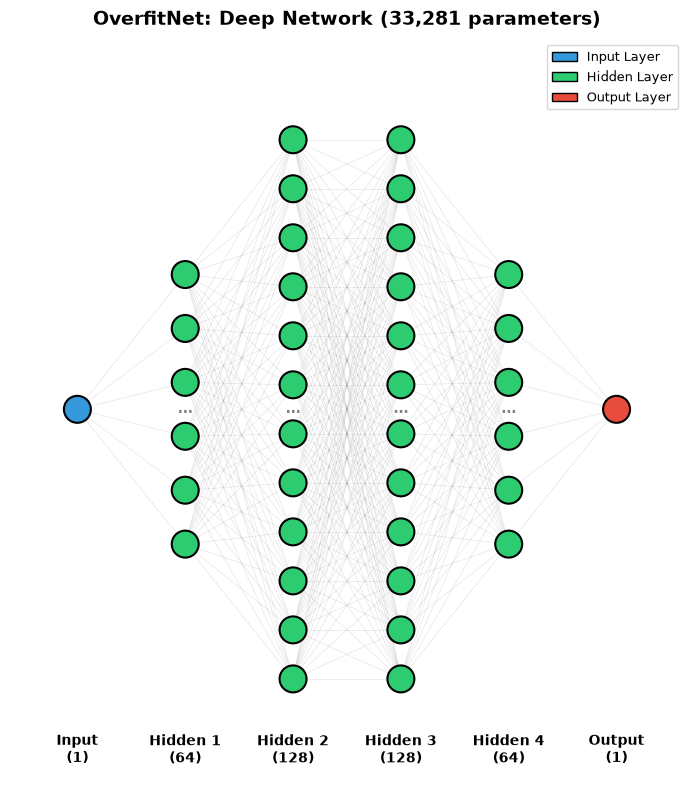

Layer connections:
  Layer 0 -> 1: 1 x 64 = 64 weights + 64 biases = 128 params
  Layer 1 -> 2: 64 x 128 = 8192 weights + 128 biases = 8320 params
  Layer 2 -> 3: 128 x 128 = 16384 weights + 128 biases = 16512 params
  Layer 3 -> 4: 128 x 64 = 8192 weights + 64 biases = 8256 params
  Layer 4 -> 5: 64 x 1 = 64 weights + 1 biases = 65 params
  Total parameters: 33,281


In [7]:
# Visualize OverfitNet architecture (used in next cell)
# This network has many more parameters - prone to overfitting with small datasets!
visualize_nn([1, 64, 128, 128, 64, 1], "OverfitNet: Deep Network (33,281 parameters)")

In [8]:
# Overfit
# Run this cell multiple times to toggle between states
# First run: shows all parameters as 0
# Second run: performs gradient descent
# Third run: resets to 0, etc.

import os

# Toggle state using an environment variable
state_file = '/tmp/nn_toggle_state.txt'
if os.path.exists(state_file):
    with open(state_file, 'r') as f:
        current_state = int(f.read().strip())
else:
    current_state = 0

# Toggle to next state
next_state = 1 - current_state
with open(state_file, 'w') as f:
    f.write(str(next_state))

# # Define a simple neural network 
# class SimpleNet(nn.Module):
#     def __init__(self):
#         super(SimpleNet, self).__init__()
#         self.fc1 = nn.Linear(1, 12)
#         self.fc2 = nn.Linear(12, 1)

#     def forward(self, x):
#         x = torch.sigmoid(self.fc1(x))
#         return self.fc2(x)

# # Create the model
# model = SimpleNet()

 # Overfitting-prone neural network
class OverfitNet(nn.Module):
    def __init__(self):
        super(OverfitNet, self).__init__()
        self.fc1 = nn.Linear(1, 64)
        self.fc2 = nn.Linear(64, 128)
        self.fc3 = nn.Linear(128, 128)
        self.fc4 = nn.Linear(128, 64)
        self.fc5 = nn.Linear(64, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.relu(self.fc3(x))
        x = torch.relu(self.fc4(x))
        return self.fc5(x)

model = OverfitNet()

# class OverfitNet(nn.Module):
#       def __init__(self):
#           super(OverfitNet, self).__init__()
#           self.fc1 = nn.Linear(1, 32)
#           self.fc2 = nn.Linear(32, 32)
#           self.fc3 = nn.Linear(32, 1)

#       def forward(self, x):
#           x = torch.relu(self.fc1(x))
#           x = torch.relu(self.fc2(x))
#           return self.fc3(x)

# model = OverfitNet()


if current_state == 0:
    model = OverfitNet()  # a fresh, untrained network
    # STATE 0: Show all parameters as zero
    with torch.no_grad():
        for param in model.parameters():
            param.zero_()
    
    # Create visualization with zero parameters
    trace_data = go.Scatter(x=x, y=y, mode='markers', name='Data')
    trace_fit = go.Scatter(
        x=x,
        y=model(x_normalized).detach().numpy().flatten(),
        mode='lines',
        name='Predicted'
    )
    
    parameter_values = flatten_tensors(list(model.parameters()))
    colors = ['red' if val < 0 else 'green' for val in parameter_values]
    trace_parameters = go.Bar(
        x=list(range(len(parameter_values))), 
        y=parameter_values,
        name='Parameters',
        marker_color=colors
    )
    
    trace_loss = go.Scatter(
        x=[0],
        y=[0],
        mode='lines',
        name='Loss',
        line=dict(color='blue')
    )
    
    fig = make_subplots(
        rows=2, cols=2, 
        column_widths=[0.7, 0.3],
        row_heights=[0.6, 0.4],
        subplot_titles=('Data Fit', 'Parameters', 'Training Loss'),
        specs=[[{"rowspan": 2}, {}],
               [None, {}]]
    )
    
    fig.add_trace(trace_data, row=1, col=1)
    fig.add_trace(trace_fit, row=1, col=1)
    fig.add_trace(trace_parameters, row=1, col=2)
    fig.add_trace(trace_loss, row=2, col=2)
    
    fig.update_yaxes(range=[-2, 2], row=1, col=2)
    fig.update_xaxes(row=1, col=1)
    fig.update_xaxes(row=1, col=2)
    fig.update_xaxes(row=2, col=2)
    fig.update_yaxes(row=1, col=1)
    fig.update_yaxes(row=1, col=2)
    fig.update_yaxes(range=[0, None], row=2, col=2)
    
    fig.update_layout(
        title='Parameters Initialized to Zero - Run again to train', 
        width=1400, 
        height=800,
        showlegend=True
    )
    
    fig.show()

else:
    # STATE 1: Perform gradient descent
    # Create a fresh model for training
    model = OverfitNet()
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.002) #lr=0.003)
    
    num_epochs = 80000
    losses = []
    
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        outputs = model(x_normalized)
        loss = criterion(outputs, y_tensor)
        loss.backward()
        optimizer.step()
        
        losses.append(loss.item())

        if epoch == 0 or (epoch+1) % 500 == 0:
            clear_output(wait=True)
            
            trace_data = go.Scatter(x=x, y=y, mode='markers', name='Data')
            # trace_fit_updated = go.Scatter(
            #     x=x,
            #     y=model(x_normalized).detach().numpy().flatten(),
            #     mode='lines',
            #     name='Predicted'
            # )
            # Dense x for plotting - reveals wiggles between training points

            x_plot = np.linspace(x.min(), x.max(), 500)
            x_plot_tensor = torch.tensor(x_plot, dtype=torch.float32)
            x_plot_normalized = ((x_plot_tensor - x_min) / (x_max - x_min)).unsqueeze(1)

            trace_fit_updated = go.Scatter(
                x=x_plot,
                y=model(x_plot_normalized).detach().numpy().flatten(),
                mode='lines',
                name='Predicted'
            )
            
            parameter_values = flatten_tensors(list(model.parameters()))
            colors = ['red' if val < 0 else 'green' for val in parameter_values]
            # trace_parameters = go.Bar(
            #     x=list(range(len(parameter_values))), 
            #     y=parameter_values,
            #     name='Parameters',
            #     marker_color=colors
            # )
            first_layer_params = torch.cat([model.fc1.weight.flatten(), model.fc1.bias]).detach().numpy()
            trace_parameters = go.Bar(
                x=list(range(len(first_layer_params))),
                y=first_layer_params,
                name='Layer 1 Parameters',
                marker_color=['red' if v < 0 else 'green' for v in first_layer_params]
            )
            
            trace_loss = go.Scatter(
                x=list(range(len(losses))),
                y=losses,
                mode='lines',
                name='Loss',
                line=dict(color='blue')
            )
            
            fig = make_subplots(
                rows=2, cols=2, 
                column_widths=[0.7, 0.3],
                row_heights=[0.6, 0.4],
                subplot_titles=('Data Fit', 'Parameters', 'Training Loss'),
                specs=[[{"rowspan": 2}, {}],
                       [None, {}]]
            )
            
            fig.add_trace(trace_data, row=1, col=1)
            fig.add_trace(trace_fit_updated, row=1, col=1)
            fig.add_trace(trace_parameters, row=1, col=2)
            fig.add_trace(trace_loss, row=2, col=2)

            fig.update_yaxes(range=[-2, 2], row=1, col=2)
            fig.update_xaxes(row=1, col=1)
            fig.update_xaxes(row=1, col=2)
            fig.update_xaxes(row=2, col=2)
            fig.update_yaxes(row=1, col=1)
            fig.update_yaxes(row=1, col=2)
            fig.update_yaxes(range=[0, None], row=2, col=2)

            fig.update_layout(
                title=f'Epoch {epoch+1}/{num_epochs}, Loss: {loss.item():.4f}', 
                width=1400, 
                height=800,
                showlegend=True
            )
            
            fig.show()

In [9]:
# Create data large data
np.random.seed(42)
xr = np.linspace(0, 2*np.pi, 1000)  

# Combine multiple sine and cosine functions
yr = np.sin(xr) + 0.5*np.sin(2*xr) + 0.3*np.cos(3*xr) + 0.6*np.sin(4*xr) + 0.1*np.random.randn(1000)

# Convert data to PyTorch tensors
xr_tensor = torch.tensor(xr, dtype=torch.float32).view(-1, 1)
yr_tensor = torch.tensor(yr, dtype=torch.float32).view(-1, 1)

# Normalize the x data for better training performance
xr_min, xr_max = xr_tensor.min(), xr_tensor.max()
xr_normalized = (xr_tensor - xr_min) / (xr_max - xr_min)

In [10]:
# Same OverfitNet architecture (33,281 params) - but now with MORE DATA to prevent overfitting!
# Compare: 104 data points (overfit) vs 1000 data points (no overfit)
#visualize_nn([1, 64, 128, 128, 64, 1], "OverfitNet with More Data: Same 33,281 params, but 1000 training points")

In [11]:
# Overfit prevented with significant data + early stopping
# Run this cell multiple times to toggle between states
# First run: shows all parameters as 0
# Second run: performs gradient descent
# Third run: resets to 0, etc.

import os

# Toggle state using an environment variable
state_file = '/tmp/nn3_toggle_state.txt'
if os.path.exists(state_file):
    with open(state_file, 'r') as f:
        current_state = int(f.read().strip())
else:
    current_state = 0

# Toggle to next state
next_state = 1 - current_state
with open(state_file, 'w') as f:
    f.write(str(next_state))

# Overfitting-prone neural network
class OverfitNet(nn.Module):
    def __init__(self):
        super(OverfitNet, self).__init__()
        self.fc1 = nn.Linear(1, 64)
        self.fc2 = nn.Linear(64, 128)
        self.fc3 = nn.Linear(128, 128)
        self.fc4 = nn.Linear(128, 64)
        self.fc5 = nn.Linear(64, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.relu(self.fc3(x))
        x = torch.relu(self.fc4(x))
        return self.fc5(x)

model = OverfitNet()

if current_state == 0:
    model = OverfitNet()  # a fresh, untrained network
    # STATE 0: Show all parameters as zero
    with torch.no_grad():
        for param in model.parameters():
            param.zero_()
    
    # Create visualization with zero parameters
    trace_data = go.Scatter(x=xr, y=yr, mode='markers', name='Data')
    trace_fit = go.Scatter(
        x=xr,
        y=model(xr_normalized).detach().numpy().flatten(),
        mode='lines',
        name='Predicted'
    )
    
    parameter_values = flatten_tensors(list(model.parameters()))
    colors = ['red' if val < 0 else 'green' for val in parameter_values]
    trace_parameters = go.Bar(
        x=list(range(len(parameter_values))), 
        y=parameter_values,
        name='Parameters',
        marker_color=colors
    )
    
    trace_loss = go.Scatter(
        x=[0],
        y=[0],
        mode='lines',
        name='Loss',
        line=dict(color='blue')
    )
    
    fig = make_subplots(
        rows=2, cols=2, 
        column_widths=[0.7, 0.3],
        row_heights=[0.6, 0.4],
        subplot_titles=('Data Fit', 'Parameters', 'Training Loss'),
        specs=[[{"rowspan": 2}, {}],
               [None, {}]]
    )
    
    fig.add_trace(trace_data, row=1, col=1)
    fig.add_trace(trace_fit, row=1, col=1)
    fig.add_trace(trace_parameters, row=1, col=2)
    fig.add_trace(trace_loss, row=2, col=2)
    
    fig.update_yaxes(range=[-2, 2], row=1, col=2)
    fig.update_xaxes(row=1, col=1)
    fig.update_xaxes(row=1, col=2)
    fig.update_xaxes(row=2, col=2)
    fig.update_yaxes(row=1, col=1)
    fig.update_yaxes(row=1, col=2)
    fig.update_yaxes(range=[0, None], row=2, col=2)
    
    fig.update_layout(
        title='Parameters Initialized to Zero - Run again to train', 
        width=1400, 
        height=800,
        showlegend=True
    )
    
    fig.show()

else:
    # STATE 1: Perform gradient descent with early stopping
    model = OverfitNet()
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.003)
    
    num_epochs = 10000
    losses = []
    
    # Early stopping parameters
    patience = 500  # Stop if no improvement for this many epochs
    min_delta = 1e-6  # Minimum change to count as improvement
    best_loss = float('inf')
    epochs_without_improvement = 0
    best_model_state = None
    stopped_early = False
    
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        outputs = model(xr_normalized)
        loss = criterion(outputs, yr_tensor)
        loss.backward()
        optimizer.step()
        
        current_loss = loss.item()
        losses.append(current_loss)
        
        # Early stopping check
        if current_loss < best_loss - min_delta:
            best_loss = current_loss
            epochs_without_improvement = 0
            best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            epochs_without_improvement += 1
        
        if epochs_without_improvement >= patience:
            stopped_early = True
            # Restore best model
            if best_model_state is not None:
                model.load_state_dict(best_model_state)
            break

        if epoch == 0 or (epoch+1) % 200 == 0:
            clear_output(wait=True)
            
            trace_data = go.Scatter(x=xr, y=yr, mode='markers', name='Data')
            
            # Dense x for plotting
            x_plot = np.linspace(xr.min(), xr.max(), 500)
            x_plot_tensor = torch.tensor(x_plot, dtype=torch.float32)
            x_plot_normalized = ((x_plot_tensor - xr_min) / (xr_max - xr_min)).unsqueeze(1)

            trace_fit_updated = go.Scatter(
                x=x_plot,
                y=model(x_plot_normalized).detach().numpy().flatten(),
                mode='lines',
                name='Predicted'
            )
            
            first_layer_params = torch.cat([model.fc1.weight.flatten(), model.fc1.bias]).detach().numpy()
            trace_parameters = go.Bar(
                x=list(range(len(first_layer_params))),
                y=first_layer_params,
                name='Layer 1 Parameters',
                marker_color=['red' if v < 0 else 'green' for v in first_layer_params]
            )
            
            trace_loss = go.Scatter(
                x=list(range(len(losses))),
                y=losses,
                mode='lines',
                name='Loss',
                line=dict(color='blue')
            )
            
            fig = make_subplots(
                rows=2, cols=2, 
                column_widths=[0.7, 0.3],
                row_heights=[0.6, 0.4],
                subplot_titles=('Data Fit', 'Parameters', 'Training Loss'),
                specs=[[{"rowspan": 2}, {}],
                       [None, {}]]
            )
            
            fig.add_trace(trace_data, row=1, col=1)
            fig.add_trace(trace_fit_updated, row=1, col=1)
            fig.add_trace(trace_parameters, row=1, col=2)
            fig.add_trace(trace_loss, row=2, col=2)

            fig.update_yaxes(range=[-2, 2], row=1, col=2)
            fig.update_xaxes(row=1, col=1)
            fig.update_xaxes(row=1, col=2)
            fig.update_xaxes(row=2, col=2)
            fig.update_yaxes(row=1, col=1)
            fig.update_yaxes(row=1, col=2)
            fig.update_yaxes(range=[0, None], row=2, col=2)

            fig.update_layout(
                title=f'Epoch {epoch+1}/{num_epochs}, Loss: {current_loss:.4f} (Best: {best_loss:.4f}, Patience: {patience - epochs_without_improvement})', 
                width=1400, 
                height=800,
                showlegend=True
            )
            
            fig.show()
    
    # Final visualization after training completes
    clear_output(wait=True)
    
    trace_data = go.Scatter(x=xr, y=yr, mode='markers', name='Data')
    x_plot = np.linspace(xr.min(), xr.max(), 500)
    x_plot_tensor = torch.tensor(x_plot, dtype=torch.float32)
    x_plot_normalized = ((x_plot_tensor - xr_min) / (xr_max - xr_min)).unsqueeze(1)
    
    trace_fit_updated = go.Scatter(
        x=x_plot,
        y=model(x_plot_normalized).detach().numpy().flatten(),
        mode='lines',
        name='Predicted'
    )
    
    first_layer_params = torch.cat([model.fc1.weight.flatten(), model.fc1.bias]).detach().numpy()
    trace_parameters = go.Bar(
        x=list(range(len(first_layer_params))),
        y=first_layer_params,
        name='Layer 1 Parameters',
        marker_color=['red' if v < 0 else 'green' for v in first_layer_params]
    )
    
    trace_loss = go.Scatter(
        x=list(range(len(losses))),
        y=losses,
        mode='lines',
        name='Loss',
        line=dict(color='blue')
    )
    
    fig = make_subplots(
        rows=2, cols=2, 
        column_widths=[0.7, 0.3],
        row_heights=[0.6, 0.4],
        subplot_titles=('Data Fit', 'Parameters', 'Training Loss'),
        specs=[[{"rowspan": 2}, {}],
               [None, {}]]
    )
    
    fig.add_trace(trace_data, row=1, col=1)
    fig.add_trace(trace_fit_updated, row=1, col=1)
    fig.add_trace(trace_parameters, row=1, col=2)
    fig.add_trace(trace_loss, row=2, col=2)

    fig.update_yaxes(range=[-2, 2], row=1, col=2)
    fig.update_yaxes(range=[0, None], row=2, col=2)

    status = f"EARLY STOPPING at epoch {len(losses)}" if stopped_early else f"Completed {num_epochs} epochs"
    fig.update_layout(
        title=f'{status} | Final Loss: {losses[-1]:.4f} | Best Loss: {best_loss:.4f}', 
        width=1400, 
        height=800,
        showlegend=True
    )
    
    fig.show()

# Complex Loss Surface Visualization

Unlike linear regression which has a simple convex "bowl" loss surface with a single global minimum, neural networks have **non-convex loss landscapes** with multiple local minima, saddle points, and plateaus.

To visualize this, we create a minimal neural network with only **2 trainable parameters** so we can compute and plot the complete loss surface in 3D.

**Network architecture:**
- Input → 1 hidden neuron (sigmoid activation) → Output
- We freeze the output weight to 1, training only:
  - `w`: input-to-hidden weight  
  - `b`: hidden neuron bias
- The network computes: `output = sigmoid(w·x + b)`

This simple non-linear model produces a complex loss surface that gradient descent must navigate.

In [12]:
# Complex Loss Surface - 2 Parameter Neural Network
# Visualize the non-convex loss landscape of a minimal neural network

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import plotly.graph_objects as go
from IPython.display import clear_output
import time
import os

# --- TOGGLE LOGIC ---
state_file = '/tmp/loss_surface_toggle.txt'
if os.path.exists(state_file):
    with open(state_file, 'r') as f:
        current_state = int(f.read().strip())
else:
    current_state = 0

next_state = 1 - current_state
with open(state_file, 'w') as f:
    f.write(str(next_state))

# --- 1. CREATE NON-LINEAR DATA ---
np.random.seed(42)
n_points = 50

# Create data that requires non-linear fitting
x_surf = np.linspace(-2, 2, n_points)
# Target: a step-like function (sigmoid-ish shape)
y_surf = 1 / (1 + np.exp(-2 * x_surf)) + 0.1 * np.random.randn(n_points)

x_surf_tensor = torch.tensor(x_surf, dtype=torch.float32).view(-1, 1)
y_surf_tensor = torch.tensor(y_surf, dtype=torch.float32).view(-1, 1)

# --- 2. DEFINE MINIMAL 2-PARAMETER NETWORK ---
class TwoParamNet(nn.Module):
    """
    Minimal network with only 2 trainable parameters:
    - w: input weight
    - b: bias
    Output = sigmoid(w * x + b)
    """
    def __init__(self, w_init=0.0, b_init=0.0):
        super().__init__()
        self.w = nn.Parameter(torch.tensor([w_init]))
        self.b = nn.Parameter(torch.tensor([b_init]))
    
    def forward(self, x):
        return torch.sigmoid(self.w * x + self.b)

# --- 3. PRE-COMPUTE LOSS SURFACE ---
# Range of parameter values to explore
w_range = np.linspace(-5, 8, 60)
b_range = np.linspace(-6, 6, 60)
W_grid, B_grid = np.meshgrid(w_range, b_range)
loss_surface = np.zeros_like(W_grid)

# Compute MSE loss at each (w, b) point
for i in range(W_grid.shape[0]):
    for j in range(W_grid.shape[1]):
        w_val = W_grid[i, j]
        b_val = B_grid[i, j]
        # Compute prediction: sigmoid(w*x + b)
        pred = 1 / (1 + np.exp(-(w_val * x_surf + b_val)))
        loss_surface[i, j] = np.mean((y_surf - pred) ** 2)

# --- 4. VISUALIZATION FUNCTION ---
camera_view = dict(eye=dict(x=1.8, y=1.8, z=1.0))

def create_loss_surface_figure(path_w, path_b, path_loss, title, show_path=True):
    fig = go.Figure()
    
    # Loss surface
    fig.add_trace(go.Surface(
        x=W_grid, y=B_grid, z=loss_surface,
        colorscale='Viridis', opacity=0.85,
        showscale=True,
        colorbar=dict(title='Loss', x=1.02),
        name='Loss Surface'
    ))
    
    if show_path and len(path_w) > 0:
        # Gradient descent path
        fig.add_trace(go.Scatter3d(
            x=path_w, y=path_b, z=path_loss,
            mode='lines+markers',
            line=dict(color='red', width=6),
            marker=dict(size=3, color='red'),
            name='Optimization Path'
        ))
        
        # Current position (yellow ball)
        fig.add_trace(go.Scatter3d(
            x=[path_w[-1]], y=[path_b[-1]], z=[path_loss[-1]],
            mode='markers',
            marker=dict(size=12, color='yellow', symbol='circle',
                       line=dict(color='black', width=2)),
            name='Current Position'
        ))
        
        # Starting position (white ball)
        fig.add_trace(go.Scatter3d(
            x=[path_w[0]], y=[path_b[0]], z=[path_loss[0]],
            mode='markers',
            marker=dict(size=10, color='white', symbol='circle',
                       line=dict(color='black', width=2)),
            name='Start'
        ))
    
    fig.update_layout(
        title=dict(text=title, font=dict(size=16)),
        scene=dict(
            xaxis_title='Weight (w)',
            yaxis_title='Bias (b)',
            zaxis_title='Loss (MSE)',
            camera=camera_view,
            aspectmode='manual',
            aspectratio=dict(x=1, y=1, z=0.7)
        ),
        width=900, height=700,
        showlegend=False,
        margin=dict(l=0, r=0, b=0, t=60)
    )
    
    return fig

# --- 5. EXECUTION ---
# Starting position (intentionally in a tricky spot)
init_w, init_b = -3.0, 4.0

if current_state == 0:
    # STATE 0: Show surface with starting point only
    init_loss = np.mean((y_surf - 1 / (1 + np.exp(-(init_w * x_surf + init_b)))) ** 2)
    
    fig = create_loss_surface_figure(
        [init_w], [init_b], [init_loss],
        'Neural Network Loss Surface - Run again to start gradient descent'
    )
    fig.show()
    
    print("Notice the complex landscape with valleys, ridges, and flat regions.")
    print("Compare this to the simple convex bowl of linear regression!")
    print(f"\nStarting position: w={init_w:.1f}, b={init_b:.1f}, loss={init_loss:.4f}")

else:
    # STATE 1: Animate gradient descent
    model = TwoParamNet(w_init=init_w, b_init=init_b)
    optimizer = optim.Adam(model.parameters(), lr=0.1)
    criterion = nn.MSELoss()
    
    # Track path
    path_w = [init_w]
    path_b = [init_b]
    init_loss = np.mean((y_surf - 1 / (1 + np.exp(-(init_w * x_surf + init_b)))) ** 2)
    path_loss = [init_loss]
    
    # Show initial state
    fig = create_loss_surface_figure(path_w, path_b, path_loss, 'Epoch 0 | Starting gradient descent...')
    fig.show()
    time.sleep(0.5)
    
    num_epochs = 200
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        outputs = model(x_surf_tensor)
        loss = criterion(outputs, y_surf_tensor)
        loss.backward()
        optimizer.step()
        
        # Record position
        w_curr = model.w.item()
        b_curr = model.b.item()
        loss_curr = loss.item()
        
        path_w.append(w_curr)
        path_b.append(b_curr)
        path_loss.append(loss_curr)
        
        # Update visualization
        if (epoch + 1) % 5 == 0:
            clear_output(wait=True)
            fig = create_loss_surface_figure(
                path_w, path_b, path_loss,
                f'Epoch {epoch+1}/{num_epochs} | w={w_curr:.2f}, b={b_curr:.2f} | Loss: {loss_curr:.4f}'
            )
            fig.show()
            time.sleep(0.05)
    
    # Final summary
    print(f"\nOptimization complete!")
    print(f"  Start:  w={init_w:.2f}, b={init_b:.2f}, loss={path_loss[0]:.4f}")
    print(f"  Final:  w={path_w[-1]:.2f}, b={path_b[-1]:.2f}, loss={path_loss[-1]:.4f}")
    print(f"\nThe path shows how gradient descent navigates the complex landscape.")
    print("Try different starting positions by modifying init_w and init_b!")


Optimization complete!
  Start:  w=-3.00, b=4.00, loss=0.4747
  Final:  w=2.42, b=-0.23, loss=0.0092

The path shows how gradient descent navigates the complex landscape.
Try different starting positions by modifying init_w and init_b!
